# Feature Store Overview

Pulls the full history of each Feast feature view straight from the offline store (SeaweedFS) -- not a point-in-time join against an entity dataframe, since here we want every row a feature view has, not a training set for specific entities/timestamps.

In [1]:
# winterload.config must be imported before feast/dask: fsspec snapshots its FSSPEC_S3_*
# env-var config at first import, so loading .env any later breaks S3 access (see
# winterload.pipeline.features.energy_load_backfill for the same gotcha).
from winterload.config import PROJECT_ROOT

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from feast import FeatureStore
from feast.infra.offline_stores.dask import DaskOfflineStore

store = FeatureStore(repo_path=str(PROJECT_ROOT / "src/winterload/feature_repo"))


def pull_feature_view(name: str) -> pd.DataFrame:
    """The full history of a feature view, straight from its offline source."""
    fv = store.get_feature_view(name)
    job = DaskOfflineStore.pull_all_from_table_or_query(
        config=store.config,
        data_source=fv.batch_source,
        join_key_columns=fv.join_keys,
        feature_name_columns=[f.name for f in fv.features],
        timestamp_field=fv.batch_source.timestamp_field,
    )
    return job.to_df().sort_values("event_timestamp")

In [2]:
energy_load = pull_feature_view("energy_load_stats")
weather_forecast = pull_feature_view("weather_forecast_stats")
weather_measurements = pull_feature_view("weather_measurements_stats")

energy_load.shape, weather_forecast.shape, weather_measurements.shape

2026-10-25 20:47:19,761 INFO     feast.infra.registry.registry: Registry cache expired, so refreshing
2026-10-25 20:47:21,561 INFO     feast.infra.registry.registry: Registry cache expired, so refreshing
2026-10-25 20:47:23,141 INFO     feast.infra.registry.registry: Registry cache expired, so refreshing


((8784, 4), (35136, 5), (35136, 5))

## Energy load over time

All backfilled days concatenated, per bidding zone.

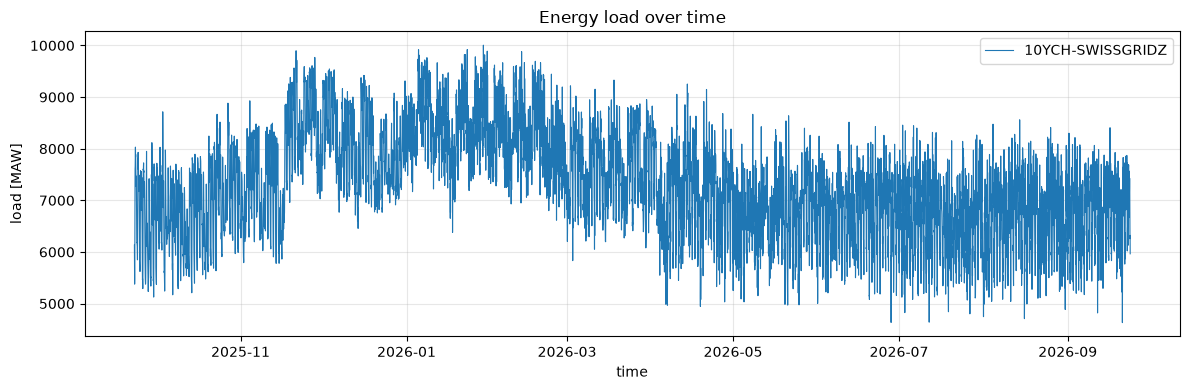

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
for zone, group in energy_load.groupby("bidding_zone_id"):
    ax.plot(group["event_timestamp"], group["quantity"], label=zone, linewidth=0.8)
ax.set_xlabel("time")
ax.set_ylabel(f"load [{energy_load['unit'].iloc[0]}]")
ax.set_title("Energy load over time")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()

## Weather: forecast vs. measurement, monthly

`weather_forecast_stats` holds the 16-39h-ahead forecast as it would have been known at the time; `weather_measurements_stats` holds what was actually observed. Averaged across cities and resampled to monthly means to show how closely the forecast tracks reality over the backfilled history.

/var/folders/6x/fs59lcy52zb701jk8jgjkxsw0000gn/T/ipykernel_86627/849415808.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  xlim = (months.min() - pd.Timedelta(days=15), months.max() + pd.Timedelta(days=15))


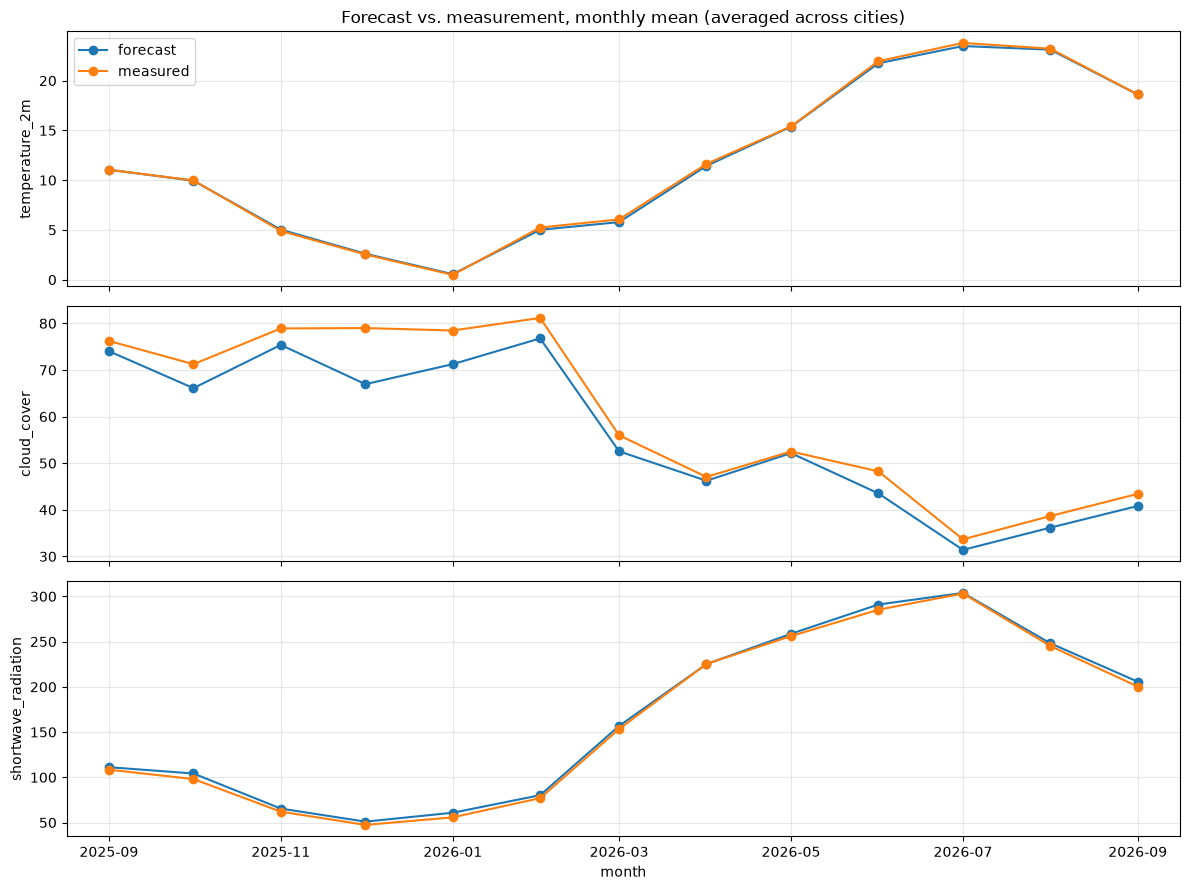

In [4]:
WEATHER_VARIABLES = ["temperature_2m", "cloud_cover", "shortwave_radiation"]

forecast_monthly = weather_forecast.set_index("event_timestamp")[WEATHER_VARIABLES].resample("MS").mean()
measured_monthly = weather_measurements.set_index("event_timestamp")[WEATHER_VARIABLES].resample("MS").mean()

# bound explicitly: matplotlib's date auto-ranging picks an absurd multi-year default when a
# resampled series has only one or two points, as it currently does with a short backfill
months = pd.concat([pd.Series(forecast_monthly.index), pd.Series(measured_monthly.index)])
xlim = (months.min() - pd.Timedelta(days=15), months.max() + pd.Timedelta(days=15))

fig, axes = plt.subplots(len(WEATHER_VARIABLES), 1, figsize=(12, 9), sharex=True)
for ax, variable in zip(axes, WEATHER_VARIABLES):
    ax.plot(forecast_monthly.index, forecast_monthly[variable], marker="o", label="forecast")
    ax.plot(measured_monthly.index, measured_monthly[variable], marker="o", label="measured")
    ax.set_ylabel(variable)
    ax.set_xlim(xlim)
    ax.grid(alpha=0.3)
axes[0].legend()
axes[0].set_title("Forecast vs. measurement, monthly mean (averaged across cities)")
axes[-1].set_xlabel("month")
fig.tight_layout()

## Energy load vs. temperature

A third, more exploratory chart: whether colder/warmer measured temperature (averaged across cities, hourly) lines up with higher/lower load -- the core hypothesis behind using weather as a feature for load forecasting.

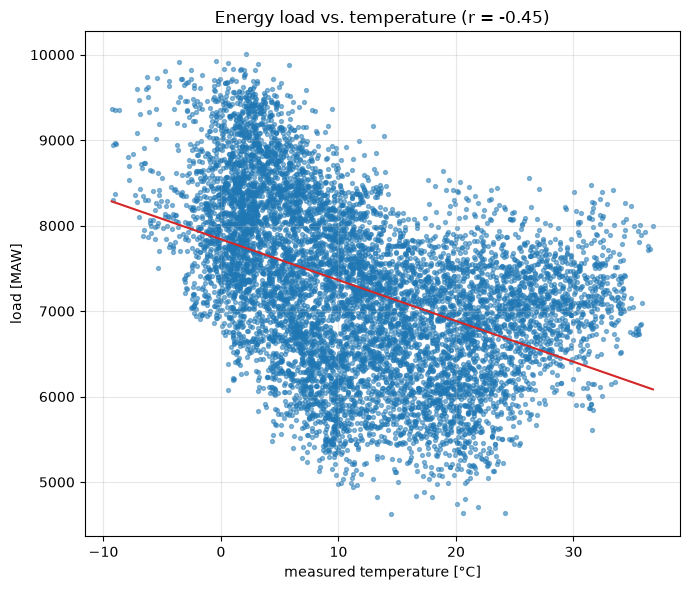

In [5]:
hourly_temperature = weather_measurements.groupby("event_timestamp")["temperature_2m"].mean()
joined = energy_load.set_index("event_timestamp")[["quantity"]].join(hourly_temperature, how="inner")
correlation = joined["quantity"].corr(joined["temperature_2m"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(joined["temperature_2m"], joined["quantity"], s=8, alpha=0.5)
slope, intercept = np.polyfit(joined["temperature_2m"], joined["quantity"], 1)
x_fit = np.array([joined["temperature_2m"].min(), joined["temperature_2m"].max()])
ax.plot(x_fit, slope * x_fit + intercept, color="tab:red")
ax.set_xlabel("measured temperature [°C]")
ax.set_ylabel(f"load [{energy_load['unit'].iloc[0]}]")
ax.set_title(f"Energy load vs. temperature (r = {correlation:.2f})")
ax.grid(alpha=0.3)
fig.tight_layout()